# IS 4487 Assignment 6: Data Cleaning with Airbnb Listings

In this assignment, you will:
- Load a raw Airbnb listings dataset
- Identify and resolve missing or inconsistent data
- Decide what data to drop, keep, or clean
- Save a clean dataset to use in Assignment 7

## Why This Matters

Data cleaning is one of the most important steps in any analysis — but it's often the least visible. Airbnb hosts, managers, and policy teams rely on clean data to make decisions. This assignment gives you experience cleaning raw data and justifying your choices so others can understand your process.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_06_data_cleaning.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>



## Dataset Description

The dataset you'll be using is a **detailed Airbnb listing file**, available from [Inside Airbnb](https://insideairbnb.com/get-the-data/).

Each row represents one property listing. The columns include:

- **Host attributes** (e.g., host ID, host name, host response time)
- **Listing details** (e.g., price, room type, minimum nights, availability)
- **Location data** (e.g., neighborhood, latitude/longitude)
- **Property characteristics** (e.g., number of bedrooms, amenities, accommodates)
- **Calendar/booking variables** (e.g., last review date, number of reviews)

📌 The schema is consistent across cities, so you can expect similar columns regardless of the location you choose.


## 1. Choose a City & Upload Your Dataset

📥 Follow these steps:

1. Go to: [https://insideairbnb.com/get-the-data/](https://insideairbnb.com/get-the-data/)
2. Choose a city you’re interested in.
3. Download the file named: **`listings.csv.gz`** under that city.
4. In your notebook:
   - Open the left sidebar
   - Click the folder icon 📁
   - Click the upload icon ⬆️ and choose your `listings.csv.gz` file
5. Use the file path `/content/listings.csv.gz` when loading your data.
6. Import standard libraries (`pandas`, `numpy`, `seaborn`, `matplotlib`)


In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv("/content/listings.csv.gz")
df.head()


,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,934859141300145599,https://www.airbnb.com/rooms/934859141300145599,20260622055616,2026-07-02,previous scrape,An Exquisite Rooftop Studio,Introducing an exquisite rooftop studio in the...,NaN,https://a0.muscache.com/pictures/miso/Hosting-...,384892315,...,NaN,NaN,NaN,NaN,NaN,1,1,0,0,NaN
1,944156894640610027,https://www.airbnb.com/rooms/944156894640610027,20260622055616,2026-06-23,city scrape,Tarrytown bungalow,Take a break and unwind at this peaceful oasis...,NaN,https://a0.muscache.com/pictures/miso/Hosting-...,13392053,...,5.00,4.75,4.25,NaN,NaN,1,0,1,0,0.12
2,1634902892490996951,https://www.airbnb.com/rooms/1634902892490996951,20260622055616,2026-06-23,city scrape,Central East Gem near running trail,Keep it simple at this peaceful and centrally-...,NaN,https://a0.muscache.com/pictures/hosting/Hosti...,266329439,...,NaN,NaN,NaN,NaN,NaN,1,1,0,0,NaN
3,1308737991593278409,https://www.airbnb.com/rooms/1308737991593278409,20260622055616,2026-06-23,city scrape,Empire,"- Accommodate up to 14 guests, 4-bedroom home<...",NaN,https://a0.muscache.com/pictures/miso/Hosting-...,398748229,...,4.93,4.80,4.61,OL2023119758,NaN,4,4,0,0,2.39
4,574582741829434703,https://www.airbnb.com/rooms/574582741829434703,20260622055616,2026-06-23,city scrape,Galaxy by AvantStay | Luxury Amenities in Austin,- Pet-friendly home<br />- Rooftop pool and lo...,NaN,https://a0.muscache.com/pictures/prohost-api/H...,434308464,...,4.52,4.97,4.90,NaN,NaN,178,178,0,0,0.60


## 2. Explore Missing Values

### Business framing:

Stakeholders don’t like surprises in the data. Missing values can break dashboards, confuse pricing models, or create blind spots for host managers.

### Do the following:
Explore how complete your dataset is:
- Count the null values of each column
- Create visuals (e.g. heatmaps, boxplots, bar charts, etc) to help show what columns are missing values
- Keep in mind which column(s) are missing too much data, you will delete these in the next step

Columns with missing values:
                              Missing Values  Percentage (%)
neighborhood_overview                  11295      100.000000
host_since                             11295      100.000000
host_response_time                     11295      100.000000
host_thumbnail_url                     11295      100.000000
host_acceptance_rate                   11295      100.000000
host_response_rate                     11295      100.000000
host_verifications                     11295      100.000000
neighbourhood                          11295      100.000000
host_total_listings_count              11295      100.000000
host_neighbourhood                     11295      100.000000
calendar_updated                       11295      100.000000
instant_bookable                       11295      100.000000
neighbourhood_group_cleansed           11295      100.000000
license                                 8211       72.695883
host_about                              3868       34.24

/tmp/ipykernel_1615/1291869649.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_missing['Percentage (%)'], y=top_missing.index, palette='viridis')


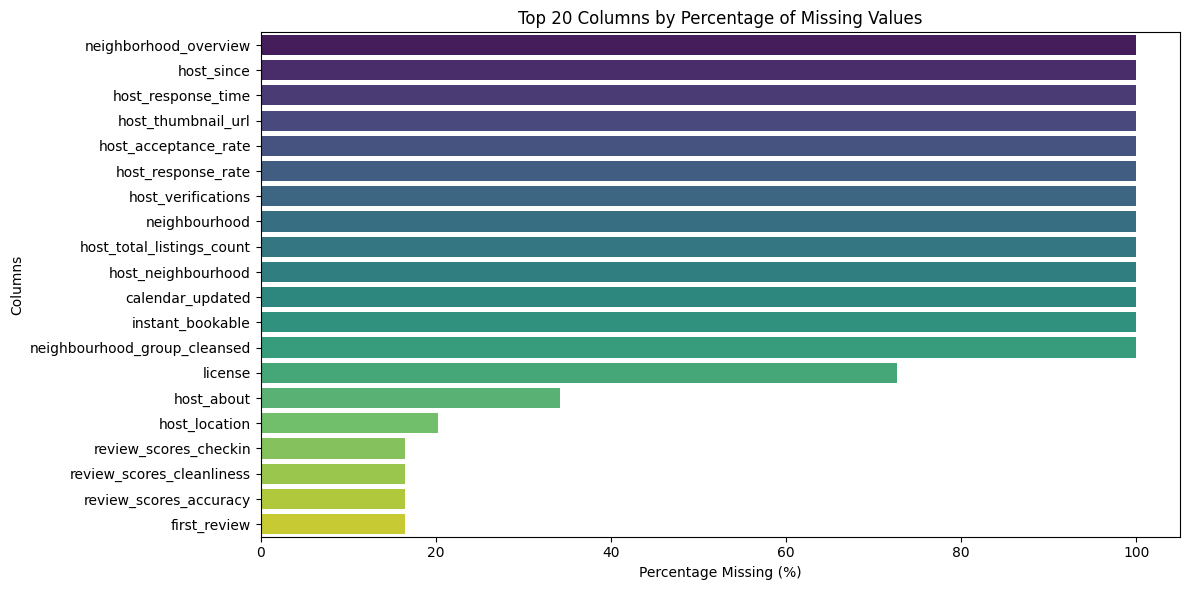

In [4]:
missing_counts = df.isnull().sum()
missing_percent = (df.isnull().sum() / len(df)) * 100

missing_df = pd.DataFrame({
    'Missing Values': missing_counts,
    'Percentage (%)': missing_percent
}).sort_values(by='Missing Values', ascending=False)

print("Columns with missing values:")
print(missing_df[missing_df['Missing Values'] > 0])
plt.figure(figsize=(12, 6))

top_missing = missing_df[missing_df['Missing Values'] > 0].head(20)
sns.barplot(x=top_missing['Percentage (%)'], y=top_missing.index, palette='viridis')

plt.title('Top 20 Columns by Percentage of Missing Values')
plt.xlabel('Percentage Missing (%)')
plt.ylabel('Columns')
plt.tight_layout()
plt.show()

### Reflection:
1. What are the top 3 columns with the most missing values?
2. Which ones are likely to create business issues?
3. Which could be safely ignored or dropped?

### ✍️ Your Response: 🔧
1. The top 3 columns with the most missing values are host_verifications, neighbourhood, and host_total_listings_count show that 100% of it is missing values in the plot.

2. Missing review scores like review_scores_checkin, review_scores_cleanliness, and review_scores_accuracy and missing host information host_location, host_about can create business issues because they prevent platform metrics from calculating host performance, evaluating guest satisfaction, or verifying host profiles.

3. Columns like license, calendar_updated, and neighbourhood_group_cleansed can be safely dropped because they either have almost 100% missing data, contain redundant information, or represent deprecated fields that aren't useful for pricing or demand analytics.


## 3. Drop Columns That Aren’t Useful

### Business framing:  

Not every column adds value. Analysts often remove columns that are too empty, irrelevant, or repetitive — especially when preparing data for others.

### Do the following:
Make a decision:

- Choose 2–4 columns to drop from your dataset
- Document your reasons for each one
- Confirm they're gone with `.head()` or `.info()`

In [5]:
columns_to_drop = ['license', 'calendar_updated', 'neighbourhood_group_cleansed']
df = df.drop(columns=columns_to_drop, errors='ignore')
print(f"Remaining number of columns: {df.shape[1]}")
df.head()

Remaining number of columns: 87


,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,934859141300145599,https://www.airbnb.com/rooms/934859141300145599,20260622055616,2026-07-02,previous scrape,An Exquisite Rooftop Studio,Introducing an exquisite rooftop studio in the...,NaN,https://a0.muscache.com/pictures/miso/Hosting-...,384892315,...,NaN,NaN,NaN,NaN,NaN,1,1,0,0,NaN
1,944156894640610027,https://www.airbnb.com/rooms/944156894640610027,20260622055616,2026-06-23,city scrape,Tarrytown bungalow,Take a break and unwind at this peaceful oasis...,NaN,https://a0.muscache.com/pictures/miso/Hosting-...,13392053,...,5.00,5.00,4.75,4.25,NaN,1,0,1,0,0.12
2,1634902892490996951,https://www.airbnb.com/rooms/1634902892490996951,20260622055616,2026-06-23,city scrape,Central East Gem near running trail,Keep it simple at this peaceful and centrally-...,NaN,https://a0.muscache.com/pictures/hosting/Hosti...,266329439,...,NaN,NaN,NaN,NaN,NaN,1,1,0,0,NaN
3,1308737991593278409,https://www.airbnb.com/rooms/1308737991593278409,20260622055616,2026-06-23,city scrape,Empire,"- Accommodate up to 14 guests, 4-bedroom home<...",NaN,https://a0.muscache.com/pictures/miso/Hosting-...,398748229,...,4.85,4.93,4.80,4.61,NaN,4,4,0,0,2.39
4,574582741829434703,https://www.airbnb.com/rooms/574582741829434703,20260622055616,2026-06-23,city scrape,Galaxy by AvantStay | Luxury Amenities in Austin,- Pet-friendly home<br />- Rooftop pool and lo...,NaN,https://a0.muscache.com/pictures/prohost-api/H...,434308464,...,4.71,4.52,4.97,4.90,NaN,178,178,0,0,0.60


### Reflection:
1. Which columns did you drop?
2. Why were they not useful from a business perspective?
3. What could go wrong if you left them in?

### ✍️ Your Response: 🔧
1. I dropped license, calendar_updated, and neighbourhood_group_cleansed.

2. The license and neighbourhood_group_cleansed contain almost 100% missing values, offering no analytical value for pricing or host insights, and the calendar_updated is a deprecated field that provides no actionable business information.

3. Leaving empty or obsolete columns clutters the dataset, increases memory usage, slows down processing times, and can confuse analysts or downstream machine learning models expecting complete data.


## 4. Fill or Fix Values in Key Columns

### Business framing:  

Let’s say your manager wants to see a map of listings with prices and review scores. If key fields are blank, the map won’t work. But not all missing values should be filled the same way.

### Do the following:
- Choose 2 columns with missing values
- Use a strategy to fill or flag those values
  - (e.g., median, “unknown”, forward-fill, or a placeholder)
- Explain what you did and why

In [6]:
review_median = df['review_scores_rating'].median()
df['review_scores_rating'] = df['review_scores_rating'].fillna(review_median)
df['host_response_rate'] = df['host_response_rate'].fillna('Unknown')
print("Missing review_scores_rating count:", df['review_scores_rating'].isnull().sum())
print("Missing host_response_rate count:", df['host_response_rate'].isnull().sum())

Missing review_scores_rating count: 0
Missing host_response_rate count: 0


### Reflection:
1. What two columns did you clean?
2. What method did you use for each, and why?
3. What risks are there in how you filled the data?

### ✍️ Your Response: 🔧
1. I cleaned review_scores_rating and host_response_rate.

2. I used review_scores_rating. It imputed missing values using the median. Median was chosen over mean because review scores tend to be skewed heavily toward 4.5–5 stars, and the median avoids distortion from extreme outliers.

I also used host_response_rate. It categorized missing values as 'Unknown' (flagging/placeholder method). Since missing rates often mean the host hasn't received enough messages or hasn't responded yet, filling with an arbitrary number like 100% or 0% would misrepresent performance.

3. Imputing median scores for unrated listings artificially inflates their rating quality, potentially recommending unverified properties to guests.

Converting missing response rates to 'Unknown' turns a potential numerical column into text/categorical, which requires special handling in future regression or quantitative models.


## 5. Convert and Clean Data Types

### Business framing:  

Sometimes columns that look like numbers are actually stored as text — which breaks calculations and slows down analysis. Common examples are price columns with dollar signs or availability stored as strings.

### Do the following:
- Identify one column with the wrong data type
- Clean and convert it into a usable format (e.g., from string to number)
- Check your work by summarizing or plotting the cleaned column

count    10321.000000
mean       352.247362
std        828.970064
min          7.950000
25%        133.100000
50%        217.000000
75%        363.000000
max      58600.500000
Name: price, dtype: float64


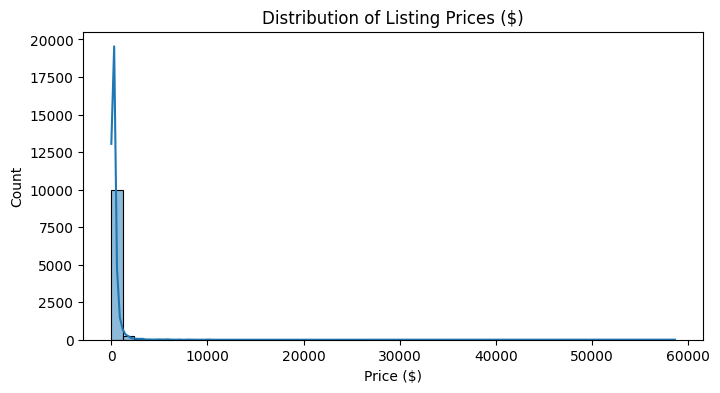

In [7]:
df['price'] = df['price'].astype(str).str.replace('$', '', regex=False)
df['price'] = df['price'].str.replace(',', '', regex=False)
df['price'] = pd.to_numeric(df['price'], errors='coerce')
print(df['price'].describe())
plt.figure(figsize=(8, 4))
sns.histplot(df['price'].dropna(), bins=50, kde=True)
plt.title('Distribution of Listing Prices ($)')
plt.xlabel('Price ($)')
plt.ylabel('Count')
plt.show()


### Reflection: :
1. What column did you fix?
2. What cleaning steps did you apply?
3. How does this help prepare the data for later use?

### ✍️ Your Response: 🔧
1. I fixed price.

2. I converted the column to a string, stripped out currency symbols ($) and commas (,), and converted the remaining value into a numeric float data type using pd.to_numeric().

3. Converting strings into numbers enables numerical computations like calculating averages, medians, and price ranges, and allows the column to be used directly in machine learning models or statistical plots.

## 6. Remove Duplicate Records

### Business framing:  

If a listing appears twice, it could inflate revenue estimates or confuse users. Airbnb needs each listing to be unique and accurate.

### Do the following:
- Check for rows that are exact duplicates
- If your data has an ID column and each ID is supposed to unique, then make sure there are no duplicate IDs
- Remove duplicates if found

In [8]:
exact_duplicates = df.duplicated().sum()
print(f"Number of exact duplicate rows: {exact_duplicates}")
id_duplicates = df['id'].duplicated().sum()
print(f"Number of duplicate IDs: {id_duplicates}")
if id_duplicates > 0:
    df = df.drop_duplicates(subset=['id'], keep='first')
    print("Duplicate IDs removed successfully.")
else:
    print("No duplicate records found.")
print(f"Total rows remaining: {df.shape[0]}")

Number of exact duplicate rows: 0
Number of duplicate IDs: 0
No duplicate records found.
Total rows remaining: 11295


### Reflection:
1. Did you find duplicates?
2. How did you decide what to drop or keep?
3. Why are duplicates risky for Airbnb teams?

### ✍️ Your Response: 🔧 🔧
1. No exact duplicate rows or duplicate listing IDs were found in the dataset (0 duplicates detected).

2. We checked for duplicates using the unique identifier column id. If duplicates had been present, the keep='first' strategy would keep the first occurrence of each listing ID and drop any subsequent duplicate rows to avoid discarding original entries.

3. Duplicate rows inflate total listing counts, skew average price calculations, and misrepresent available property inventory. This can lead to distorted market demand analysis and incorrect business forecasts for stakeholders.

## 7. Export Cleaned Data

Before wrapping up, export your cleaned Airbnb dataset to a CSV file. You'll need this file for **Assignment 7**, where you'll perform data transformation techniques.

### Do the following:
Make sure your data has:
- Cleaned and consistent column values
- Proper data types for each column
- Any unnecessary columns removed

This file should be the version of your dataset that you’d feel confident sharing with a teammate or using for deeper analysis.



```
# Explanation:
# - "cleaned_airbnb_data_6.csv" is the name of the file that will be saved
# - index=False prevents pandas from writing row numbers into the CSV
# - The file will be saved to your working directory (in Colab, you'll need to download it manually. Once you see the data in your files tab, just click on the three dots, then click “download”)
# - YOU MAY NEED TO PRESS “RUN” MULTIPLE TIMES IN ORDER FOR IT TO SHOW UP
# - FOR SOME DEVICES, IT MAY TAKE A FEW MINUTES BEFORE YOUR FILE SHOWS UP

```





In [9]:
df.to_csv('cleaned_airbnb_data_6.csv', index=False)

print("Dataset successfully exported as 'cleaned_airbnb_data_6.csv'.")

Dataset successfully exported as 'cleaned_airbnb_data_6.csv'.


## 8. Final Reflection

You’ve just cleaned a real-world Airbnb dataset — the kind of work that happens every day in analyst and data science roles.

Before you move on to data transformation in Assignment 7, take a few moments to reflect on the decisions you made and what you learned.

### Reflection:
1. Which section of the assignment was the most challenging for you? What made it challenging? Was it the coding or the application of class concepts?
2. Look back at your assignment and discuss a time when you had to drop, fix, or keep a piece of data. Why was it necessary to drop, fix, or keep that specific piece of data? (e.x. dropping a column full of null values because it has no useful information)
3. What’s one way a business team (e.g., hosts, pricing analysts, app administrators) might benefit from the cleaned version of this data?
4. If you had more time, what would you explore or clean further?
5. How does this relate to your customized learning outcome you created in canvas?


Write your response clearly in full sentences. No more than a few sentences required per response.


### ✍️ Your Response: 🔧

1. __  I found it hard handling missing values appropriately across many different columns—deciding whether to drop entire columns, impute missing values with statistics like the median, or fill them with descriptive placeholders like 'Unknown'.
2. __  Removing unhelpful/empty columns streamlined the dataset and saved memory. Cleaning string values out of price converted it into a numerical column ready for calculations, and handling missing values ensured future machine learning models or summary reports won't fail due to unexpected nulls.
3. __ Pricing analysts and app administrators can accurately evaluate average listing prices, identify market trends, and build prediction models without errors caused by missing values, formatting symbols, or duplicate entries.
4. __  I would convert date fields (such as host_since and last_review) into proper datetime objects, parse out individual features from the amenities string list, and identify or handle extreme price outliers that could distort numerical calculations.
5. __  It directly demonstrates how real world data requires structured preprocessing; such as handling null values, type conversion, and deduplication; before it can be used effectively for business decision making and predictive analytics.


## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [ ]:
!jupyter nbconvert --to html "assignment_06_data_cleaning.ipynb"